# Data Cleaning Workflow

As **discussed** in the [solvent chapter](9_Solvent.ipynb), we ran four IRC calculations: forward and reverse for the gas phase and for water (PCM). Their log files are in the `runs/` folder.

| Log file    |  Description    |
|  :---------------------------    | :-------------------------  |
| `SN2_D3h_H2O_321G_IRC.log` \& `SN2_D3h_H2O_321G_IRC_R.log` | Solvent IRC, forward and reverse
| `SN2_D3h_321G_IRC.log` \& `SN2_D3h_321G_IRC_R.log`         | Gas phase IRC, forward and reverse

In the original version of this book, the lines we needed were first pulled out of the log files with *grep* into eight small text files per calculation (stride, energy and the two C–Cl distances, forward and reverse), and those files were then cleaned up here. Now *Python* reads the log files directly, but the **cleaning and collating** job is the same: put the forward and reverse halves of the path together into one tidy table, and save it for the [plotting notebook](10_Solvent_IRC_Plots-Data.ipynb).

## Load Your Tools
Load in the modules needed for this exercise. `gamess_tools` is the book's helper module; its location for *GAMESS* is set once in `gamess_settings.py` (see the [setup page](1_Setup.ipynb)), although this notebook only reads log files and does not run *GAMESS*.

In [1]:
# ===== SETTINGS =========================================================
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import gamess_tools as gt

RUNS = Path("runs")      # the IRC log files from the solvent chapter
DATA = Path("data")      # the cleaned tables are written here

HARTREE_TO_KJMOL = 2625.5   # 1 hartree = 2625.5 kJ/mol
# ========================================================================

## Importing Raw Data

The function `gt.irc_points()` reads an IRC log file and returns one entry per point on the path. It does the work of the four *grep* commands from the original page:

| *grep* for… | gives |
| :--- | :--- |
| `AT PATH DISTANCE STOTAL` | the **stride**, the distance travelled along the path |
| `TOTAL ENERGY` | the **energy** at that point |
| `STRETCH   1  3` | the first C–Cl distance (atoms 1 and 3) |
| `STRETCH   2  3` | the second C–Cl distance (atoms 2 and 3) |

It also deals with the **step zero** problem that caught us before. The transition state is point 0. It has a stride of zero (not explicitly reported, but obvious when you think about it) and its energy is not on a `TOTAL ENERGY` line but on the first `FINAL RO-B3LYP ENERGY` line of the log file (we asked for it with `TSENGY=.TRUE.`). The C–Cl distances of point 0 are in the first table of internal coordinates. `gt.irc_points()` puts these at the top of the list. Open `gamess_tools.py` and read the function: it is about thirty lines long.

The block of code **below** sets up the file names for the solvent data. This way we can change the file names here and will not need to edit them in the document later.

In [2]:
forward_file = RUNS / "SN2_D3h_H2O_321G_IRC.log"
reverse_file = RUNS / "SN2_D3h_H2O_321G_IRC_R.log"
bonds = [(1, 3), (2, 3)]          # the two C-Cl bonds: Cl1-C3 and Cl2-C3

In [3]:
df = pd.DataFrame(gt.irc_points(forward_file, bonds))
df_r = pd.DataFrame(gt.irc_points(reverse_file, bonds))
display(df.head(3))
display(df_r.head(3))
print(len(df), "forward points and", len(df_r), "reverse points, each including the transition state")

,stride,energy,"R(1,3)","R(2,3)"
0,0.00000,-955.696974,2.392440,2.389538
1,0.29996,-955.697168,2.441993,2.340124
2,0.59989,-955.697717,2.491225,2.290456


,stride,energy,"R(1,3)","R(2,3)"
0,0.00000,-955.696974,2.392440,2.389538
1,0.29996,-955.697166,2.342517,2.438580
2,0.59990,-955.697707,2.292293,2.487251


18 forward points and 18 reverse points, each including the transition state


## Cleaning the Data

Data cleaning is **half the work** in data analysis. We need to drop empty and malformed records (each line could be considered a record in this case). We will need to drop any fields (the columns in each record are the fields) that we don't need, and **rename** the columns for what they represent.

Here the records are already tidy, because `gt.irc_points()` only keeps the numbers. The remaining jobs are these:

1. **Invert** the sign of the stride for the **reverse** run, so that the reverse half of the path lies on the negative side of the transition state.
2. **Drop** the transition state (point 0) from the reverse list. It is already the first row of the forward list and we only want it once.
3. **Append** the reverse list to the forward list and **sort** by stride.
4. Calculate the **relative energy** in kJ/mol. As in the original notebook, the highest energy on the path (the transition state) is the zero.
5. **Rename** the columns so I don't forget what they are.

In [4]:
df_r["stride"] = -df_r["stride"]           # reverse the progress for the reverse IRC
df_r = df_r.drop(index=[0])                # drop the transition state from the reverse list

data = pd.concat([df, df_r])               # combine forward and reverse data
data = data.sort_values(by="stride")       # sort the table by stride
data = data.reset_index(drop=True)         # renumber the rows 0, 1, 2, ...

max_energy = data["energy"].max()          # find the maximum energy in the list
data["E(kJ/mole)"] = (data["energy"] - max_energy) * HARTREE_TO_KJMOL

data = data.rename(columns={"R(1,3)": "C-Cl1", "R(2,3)": "C-Cl2"})
data = data[["stride", "energy", "E(kJ/mole)", "C-Cl1", "C-Cl2"]]   # column order
display(data)

,stride,energy,E(kJ/mole),C-Cl1,C-Cl2
0,-4.93950,-955.705799,-23.169524,1.958403,3.111423
1,-4.76352,-955.705798,-23.166373,1.959355,3.096822
2,-4.48436,-955.705773,-23.102311,1.961464,3.062768
3,-4.18746,-955.705713,-22.944519,1.963747,3.026581
4,-3.88874,-955.705610,-22.673567,1.966013,2.990097
5,-3.58884,-955.705456,-22.269503,1.968562,2.953269
6,-3.28889,-955.705244,-21.711846,1.970659,2.916713
7,-2.98914,-955.704958,-20.962004,1.973656,2.879458
8,-2.69255,-955.704539,-19.861919,1.985811,2.836702
9,-2.39678,-955.703924,-18.248549,2.013012,2.787310


### Documentation is Important

Take note of the **descriptions** for how I **converted** the log files into dataframes and then **processed** them into one table. This **documentation** is not a waste of time. Next week, I will have no memory of what I did. I will be able to **follow** my own work and trouble shoot any errors because of this documentation. Most importantly, others will be able to recognize my genius or **correct** my mistakes.

## Do It All Again, With a Function

In the original notebook you executed all of the cells above a second time, after changing the file names to the gas phase files. That works, but it is easy to forget a step or save a table under the wrong name. *Python* lets us **wrap** the recipe in a **function** and then use it as often as we like. The function below holds exactly the same steps as the cells above.

In [5]:
def irc_table(forward_file, reverse_file, bonds=((1, 3), (2, 3))):
    # Join the forward and reverse halves of an IRC into one table.
    df = pd.DataFrame(gt.irc_points(forward_file, bonds))
    df_r = pd.DataFrame(gt.irc_points(reverse_file, bonds))

    df_r["stride"] = -df_r["stride"]       # reverse run goes to negative stride
    df_r = df_r.drop(index=[0])            # the transition state only once

    data = pd.concat([df, df_r]).sort_values(by="stride").reset_index(drop=True)
    data["E(kJ/mole)"] = (data["energy"] - data["energy"].max()) * HARTREE_TO_KJMOL
    data = data.rename(columns={"R(1,3)": "C-Cl1", "R(2,3)": "C-Cl2"})
    return data[["stride", "energy", "E(kJ/mole)", "C-Cl1", "C-Cl2"]]


solvent = irc_table(RUNS / "SN2_D3h_H2O_321G_IRC.log", RUNS / "SN2_D3h_H2O_321G_IRC_R.log")
gasphase = irc_table(RUNS / "SN2_D3h_321G_IRC.log", RUNS / "SN2_D3h_321G_IRC_R.log")

print("Same as the table above:", solvent.equals(data))
display(gasphase.head())

Same as the table above: True


,stride,energy,E(kJ/mole),C-Cl1,C-Cl2
0,-2.08886,-955.610455,-3.714955,2.095466,2.734344
1,-2.08792,-955.610455,-3.714955,2.095449,2.734359
2,-2.08594,-955.610455,-3.714955,2.095423,2.734369
3,-1.79283,-955.610390,-3.544297,2.112965,2.689099
4,-1.49766,-955.610218,-3.092711,2.147086,2.637748


## Writing Data Files

Now that we have a set of processed data we should **write it out** so that we can **use it again** and again without having to repeat this whole processing procedure. We write two files into the `data/` folder: `SN2_IRC_Solvent_Data.txt` and `SN2_IRC_Data_GasPhase_Data.txt`. They are ordinary comma-separated text files; open one in a text editor and have a look.

In [6]:
solvent.to_csv(DATA / "SN2_IRC_Solvent_Data.txt")
gasphase.to_csv(DATA / "SN2_IRC_Data_GasPhase_Data.txt")
print(*sorted(p.name for p in DATA.glob("SN2_IRC_*.txt")), sep="\n")

SN2_IRC_Data_GasPhase_Data.txt
SN2_IRC_Solvent_Data.txt


## You're Ready to Plot

We now have the **two data tables saved** as text files. We will use them in the [next notebook](10_Solvent_IRC_Plots-Data.ipynb) where we will plot the data and see if there is a **difference** between the solvent and gas-phase calculations.

## Plots
Below are some **quick** plots of various value pairs. They confirm that my data processing did not cause any disastrous misalignments of data series. They were just used for **diagnostic** purposes (I found some really big mistakes that showed up as crazy zig-zag plots before I figured all this out).

I am leaving them here for your information. Please **proceed** to the next notebook to compare the data sets.

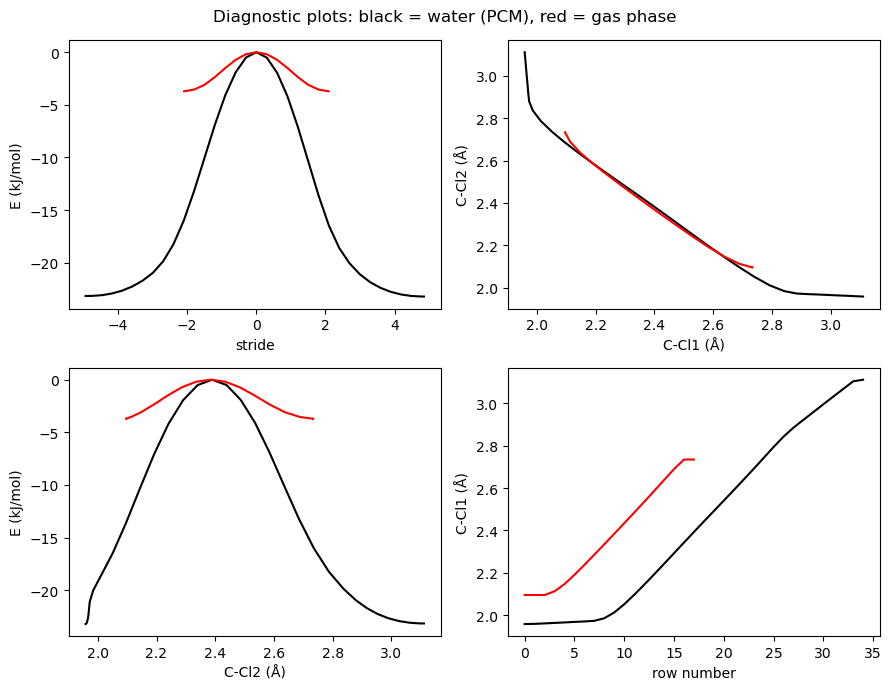

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7))
for table, colour in ((solvent, "k"), (gasphase, "r")):
    axes[0, 0].plot(table["stride"], table["E(kJ/mole)"], colour + "-")
    axes[0, 1].plot(table["C-Cl1"], table["C-Cl2"], colour + "-")
    axes[1, 0].plot(table["C-Cl2"], table["E(kJ/mole)"], colour + "-")
    axes[1, 1].plot(table.index, table["C-Cl1"], colour + "-")

axes[0, 0].set(xlabel="stride", ylabel="E (kJ/mol)")
axes[0, 1].set(xlabel="C-Cl1 (Å)", ylabel="C-Cl2 (Å)")
axes[1, 0].set(xlabel="C-Cl2 (Å)", ylabel="E (kJ/mol)")
axes[1, 1].set(xlabel="row number", ylabel="C-Cl1 (Å)")
fig.suptitle("Diagnostic plots: black = water (PCM), red = gas phase")
fig.tight_layout()
plt.show()

## AI Statement

This notebook is a revision of the original `10_Solvent_IRC_Plots.ipynb`, made with the help of Claude (Anthropic) following the author's instructions.

- **Original text kept (about 50 %).** The purpose of the notebook, the cleaning steps (invert the reverse stride, keep the transition state once, combine, sort, relative energy from the maximum), the paragraphs on data cleaning and documentation, the file names of the saved tables and the idea of the diagnostic plots are the author's.
- **Written by AI.** The input is now the four IRC log files themselves, read with the new helper `gt.irc_points()` in `gamess_tools.py`, which replaces the *grep* text files and the `pd.read_csv(sep=...)` parsing of them; the table explaining what each *grep* did; the `irc_table()` function that replaces "go back to the top and run it all again"; the four diagnostic plots drawn as one figure with both data sets.
- **Changed workflow.** The tables are written to the book's `data/` folder. Because both tables are now produced by the same function, the gas-phase table is genuinely the gas-phase result (in the original book the saved gas-phase file was a copy of the solvent file).